In [3]:
# Hadijah Tohepaly-202431078
# 1. Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [4]:
# Hadijah Tohepaly-202431078
# 2. Membaca Dataset
df = pd.read_csv("hasil_scraping.csv")

df.head()

,sku,nama_produk,maker,kategori,pack,harga,harga_sebelumnya,stock,lead_time,rating,reviews
0,NWT-10000,"Cast Iron Mug Set, Oat — Small",Fieldhouse,Tabletop,1,186.94,NaN,In stock,2 weeks,4.8,209
1,NWT-10001,"Wool Skillet, Large — Medium",Aoyama Works,Kitchen,2,137.45,NaN,In stock,2–3 days,4.5,261
2,NWT-10002,"Walnut Side Table, Large — Large",Tessa Ruiz Studio,Furniture,2,88.68,NaN,Low stock,ships today,3.2,128
3,NWT-10003,"Wool Bowl, Clay — Extra large",Aoyama Works,Tabletop,6,95.54,NaN,Low stock,4–6 weeks,4.8,165
4,NWT-10004,"Slate Vase, Ink — Natural",Brock Forge,Decor,2,386.92,NaN,Low stock,1 week,4.0,280


In [6]:
# Hadijah Tohepaly-202431078
# 3. Melihat Informasi Data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sku               200 non-null    object 
 1   nama_produk       200 non-null    object 
 2   maker             200 non-null    object 
 3   kategori          200 non-null    object 
 4   pack              200 non-null    int64  
 5   harga             200 non-null    float64
 6   harga_sebelumnya  75 non-null     float64
 7   stock             200 non-null    object 
 8   lead_time         200 non-null    object 
 9   rating            200 non-null    float64
 10  reviews           200 non-null    int64  
dtypes: float64(3), int64(2), object(6)
memory usage: 17.3+ KB


In [9]:
# Hadijah Tohepaly-202431078
# 4. Melihat Deskripsi Statistik
df.describe()

,pack,harga,harga_sebelumnya,rating,reviews
count,200.000000,200.000000,75.000000,200.000000,200.000000
mean,3.655000,463.089700,571.228000,3.999500,203.990000
std,3.633454,517.774022,619.106996,0.534677,114.021641
min,1.000000,14.810000,35.090000,3.100000,1.000000
25%,1.000000,186.670000,257.755000,3.600000,110.750000
50%,2.000000,335.255000,436.700000,3.900000,215.500000
75%,6.000000,453.657500,604.475000,4.400000,290.000000
max,12.000000,2979.070000,3784.960000,5.000000,419.000000


In [10]:
# Hadijah Tohepaly-202431078
# 5. Mengecek Data Kosong
df.isna().sum()

sku                   0
nama_produk           0
maker                 0
kategori              0
pack                  0
harga                 0
harga_sebelumnya    125
stock                 0
lead_time             0
rating                0
reviews               0
dtype: int64

In [20]:
# Hadijah Tohepaly-202431078
# 6. Melihat Nilai Unik Kolom Target
print(df["kategori"].unique())

['Tabletop' 'Kitchen' 'Furniture' 'Decor' 'Lighting' 'Textiles']


In [26]:
# Hadijah Tohepaly-202431078
# 7. Memisahkan Fitur X dan Target y
X = df[["harga", "harga_sebelumnya", "stock",
        "lead_time", "rating", "reviews"]]

y = df["kategori"]

In [28]:

# Hadijah Tohepaly-202431078
# 8. Mengubah X dan y Menjadi Array Angka

# Menyalin data fitur
X = X.copy()

# Mengatasi missing value pada harga_sebelumnya
X["harga_sebelumnya"] = X["harga_sebelumnya"].fillna(
    X["harga_sebelumnya"].median()
)

# Mengubah kolom stock menjadi angka
le_stock = LabelEncoder()
X["stock"] = le_stock.fit_transform(X["stock"])

# Mengubah kolom lead_time menjadi angka
le_lead = LabelEncoder()
X["lead_time"] = le_lead.fit_transform(X["lead_time"])

# Mengubah target kategori menjadi angka
le = LabelEncoder()
y = le.fit_transform(y)

# Mengubah X menjadi array float64
X = np.array(X, dtype=np.float64)

# Mengubah y menjadi array int64
y = np.array(y, dtype=np.int64)

print("X:")
print(X)

print("y:")
print(y)


X:
[[1.86940e+02 4.36700e+02 0.00000e+00 1.00000e+00 4.80000e+00 2.09000e+02]
 [1.37450e+02 4.36700e+02 0.00000e+00 2.00000e+00 4.50000e+00 2.61000e+02]
 [8.86800e+01 4.36700e+02 1.00000e+00 4.00000e+00 3.20000e+00 1.28000e+02]
 ...
 [2.22113e+03 4.36700e+02 0.00000e+00 3.00000e+00 3.20000e+00 2.18000e+02]
 [1.28190e+02 4.36700e+02 0.00000e+00 4.00000e+00 4.60000e+00 1.10000e+02]
 [1.87350e+02 2.30810e+02 0.00000e+00 3.00000e+00 4.30000e+00 1.05000e+02]]
y:
[4 2 1 4 0 2 3 4 4 0 2 4 3 2 3 4 2 1 5 3 4 0 2 2 0 5 3 1 4 2 2 4 4 0 2 3 0
 0 0 3 1 2 0 4 1 4 4 1 2 0 2 4 0 4 2 4 4 4 2 2 1 5 5 2 4 0 1 0 2 2 4 5 1 4
 4 0 0 5 0 0 0 2 2 5 2 4 2 4 0 2 4 4 1 4 4 4 5 5 2 4 3 2 0 0 3 5 4 2 0 5 4
 4 2 4 4 4 2 2 4 4 4 2 1 4 0 2 3 4 4 0 2 4 3 2 3 4 2 1 5 3 4 0 2 2 0 5 3 1
 4 2 2 4 4 0 2 3 0 0 0 3 1 2 0 4 1 4 4 1 2 0 2 4 0 4 2 4 4 4 2 2 1 5 5 2 4
 0 1 0 2 2 4 5 1 4 4 0 0 5 0 0]


In [47]:
# Hadijah Tohepaly-202431078
# 9. Membagi Data Latih dan Data Uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=0,
    stratify=y
)

In [41]:
# Hadijah Tohepaly-202431078
# 10. Membuat Model Decision Tree

model = DecisionTreeClassifier()

# Melatih model
model.fit(X_train, y_train)

print("Model berhasil dilatih")

Model berhasil dilatih


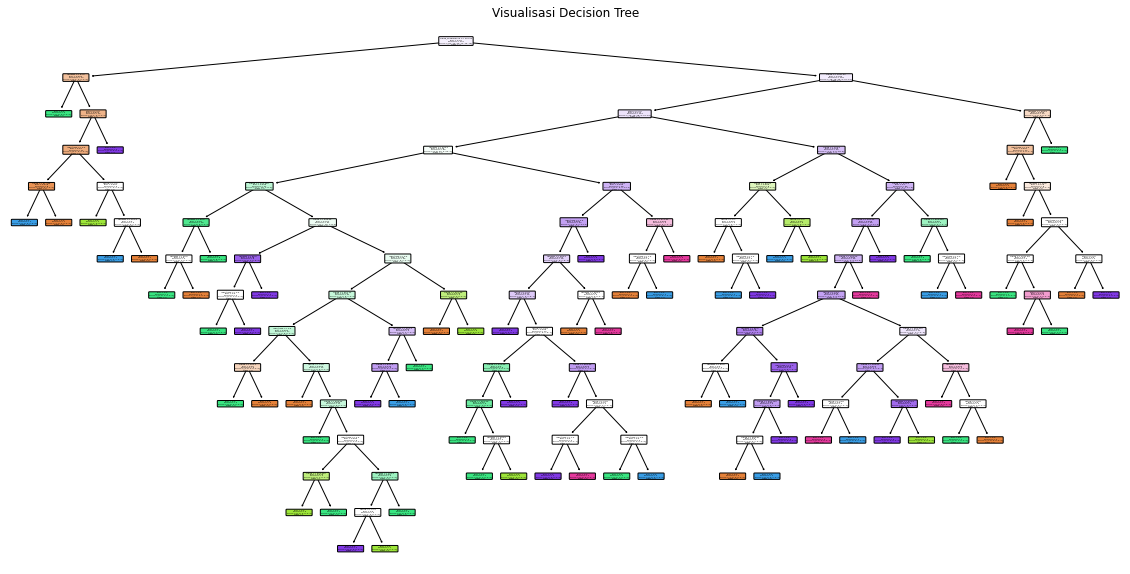

In [42]:

# Hadijah Tohepaly-202431078
# 11. Visualisasi Pohon Keputusan

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=[
        "harga",
        "harga_sebelumnya",
        "stock",
        "lead_time",
        "rating",
        "reviews"
    ],
    class_names=[str(kelas) for kelas in le.classes_],
    filled=True,
    rounded=True
)

plt.title("Visualisasi Decision Tree")
plt.show()


In [43]:
# Hadijah Tohepaly-202431078
# 12. Prediksi Menggunakan 1 Data Baru

data_baru = pd.DataFrame([{
    "harga": 186.94,
    "harga_sebelumnya": 200.00,
    "stock": "In stock",
    "lead_time": "2 weeks",
    "rating": 4.8,
    "reviews": 209
}])

# Mengubah stock dan lead_time
data_baru["stock"] = le_stock.transform(data_baru["stock"])
data_baru["lead_time"] = le_lead.transform(data_baru["lead_time"])

# Mengubah menjadi array
data_baru = np.array(data_baru, dtype=np.float64)

# Prediksi
prediksi = model.predict(data_baru)

print("Hasil Prediksi:", le.inverse_transform(prediksi))

Hasil Prediksi: [0]


In [44]:
# Hadijah Tohepaly-202431078
# 13. Menghitung Akurasi

y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Model:", akurasi)
print("Akurasi (%):", akurasi * 100)

Akurasi Model: 0.13333333333333333
Akurasi (%): 13.333333333333334


In [46]:
# Hadijah Tohepaly-202431078
# 14. Classification Report

print(classification_report(
    y_test,
    y_pred,
    target_names=[str(kelas) for kelas in le.classes_],
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.10      0.08      0.09        12
           1       0.00      0.00      0.00         5
           2       0.30      0.20      0.24        15
           3       0.00      0.00      0.00         5
           4       0.15      0.17      0.16        18
           5       0.10      0.20      0.13         5

    accuracy                           0.13        60
   macro avg       0.11      0.11      0.10        60
weighted avg       0.15      0.13      0.14        60

